# Voigt 线形（Voigt Profile）

> 参考：
> - Wikipedia, "Voigt profile," oldid 1384717701. <https://en.wikipedia.org/wiki/Voigt_profile>
> - Christian Hill, *Learning Scientific Programming with Python* (2nd ed.), Example E8.9 "The Voigt profile." <https://scipython.com/books/book2/chapter-8-scipy/examples/the-voigt-profile/>
>
> 本文是根据上述资料整理的笔记加演示代码，不是原文的转载。所有公式都用数值方法验证过。

## 背景

Voigt 线形是高斯分布和洛伦兹（柯西）分布的卷积，以 Woldemar Voigt 的名字命名：他在 1912 年的论文里用它描述气体光谱中谱线的强度分布。如果一条谱线同时受两类展宽的影响，它的形状就是 Voigt 线形：

- **高斯展宽**：非均匀展宽，比如多普勒展宽、仪器分辨率、局部环境的无序分布；
- **洛伦兹展宽**：均匀展宽，比如发射或吸收的阻尼，也就是激发态寿命（碰撞、芯能级空穴寿命）。
它广泛用于光谱学和衍射（XRD 峰形、XPS、Raman），以及大气辐射传输、类星体吸收线分析。粒子物理里也有相对论版本：相对论 Breit–Wigner 分布与高斯分布的卷积。

## 定义

中心在 0 的归一化高斯函数和洛伦兹函数：

$$
G(x;\sigma)=\frac{e^{-x^2/(2\sigma^2)}}{\sqrt{2\pi}\,\sigma},\qquad
L(x;\gamma)=\frac{\gamma}{\pi\left(\gamma^2+x^2\right)}
$$

其中 $\sigma$ 是高斯的标准差，$\gamma$ 是洛伦兹的半高半宽（HWHM），$x$ 是相对线中心的偏移。Voigt 线形就是两者的卷积：

$$
V(x;\sigma,\gamma)\equiv\int_{-\infty}^{\infty}G(x';\sigma)\,L(x-x';\gamma)\,dx'
$$

### 用 Faddeeva 函数计算

这个积分没有初等函数形式的闭式解，但可以写成 Faddeeva 函数 $w(z)=e^{-z^2}\operatorname{erfc}(-iz)$ 的实部：

$$
V(x;\sigma,\gamma)=\frac{\operatorname{Re}[w(z)]}{\sqrt{2\pi}\,\sigma},\qquad z=\frac{x+i\gamma}{\sqrt2\,\sigma}
$$

两个极限：$\sigma\to0$ 时退化为 $L(x;\gamma)$，$\gamma\to0$ 时退化为 $G(x;\sigma)$。

SciPy 用 `scipy.special.wofz` 计算 $w(z)$；从 SciPy 1.4 起，也可以直接用 `scipy.special.voigt_profile(x, sigma, gamma)`。C 语言库 [libcerf](https://jugit.fz-juelich.de/mlz/libcerf) 也提供 `voigt(x, sigma, gamma)`，精度约 13–14 位有效数字。

### 不在原点的情形

高斯中心在 $\mu_G$、洛伦兹中心在 $\mu_L$ 时，卷积的中心在 $\mu_V=\mu_G+\mu_L$，只需把 $x$ 换成 $x-\mu_V$：

$$
V(x;\mu_V,\sigma,\gamma)=\frac{\operatorname{Re}[w(z)]}{\sigma\sqrt{2\pi}},\qquad z=\frac{x-\mu_V+i\gamma}{\sigma\sqrt2}
$$

众数（峰位）和中位数都在 $\mu_V$。

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import wofz, voigt_profile, erfcx
from scipy.integrate import quad
from scipy.optimize import brentq, curve_fit

SQ2PI = np.sqrt(2 * np.pi)


def gaussian(x, sigma):
    return np.exp(-x**2 / (2 * sigma**2)) / (SQ2PI * sigma)


def lorentzian(x, gamma):
    return gamma / (np.pi * (gamma**2 + x**2))


def voigt(x, sigma, gamma, mu=0.0):
    """用 Faddeeva 函数计算的归一化 Voigt 线形"""
    z = (x - mu + 1j * gamma) / (sigma * np.sqrt(2))
    return wofz(z).real / (SQ2PI * sigma)

### 三种方法互相验证：Faddeeva、`voigt_profile`、直接数值卷积

In [20]:
sigma, gamma = 0.6, 0.4
x = np.linspace(-5, 5, 11)

v_wofz = voigt(x, sigma, gamma)
v_scipy = voigt_profile(x, sigma, gamma)
v_conv = np.array([quad(lambda t: gaussian(t, sigma) * lorentzian(xi - t, gamma), -np.inf, np.inf)[0]
                   for xi in x])

print("wofz vs voigt_profile 最大偏差:", np.abs(v_wofz - v_scipy).max())
print("wofz vs 数值卷积      最大偏差:", np.abs(v_wofz - v_conv).max())
print("面积:", quad(voigt, -np.inf, np.inf, args=(sigma, gamma))[0])

wofz vs voigt_profile 最大偏差: 2.7755575615628914e-17
wofz vs 数值卷积      最大偏差: 5.376192546702185e-12
面积: 1.0


### 用 HWHM 作参数：仿照 scipython 例题画三条线形

scipython 的例题用两个 HWHM 作参数：高斯的 HWHM $\alpha=\sigma\sqrt{2\ln2}$，洛伦兹的 HWHM $\gamma$。取 $\alpha=\gamma=0.1$，把面积都为 1 的高斯、洛伦兹、Voigt 画在一起比较（下面是按同样思路写的代码）：

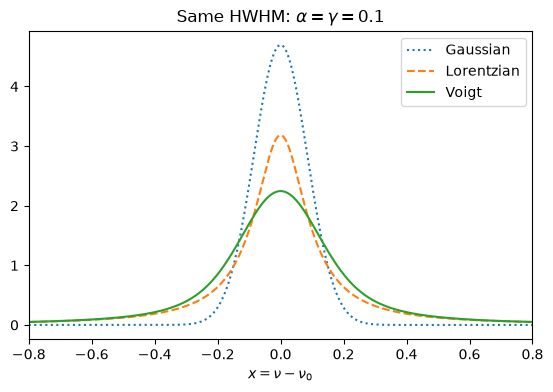

In [21]:
alpha, gamma = 0.1, 0.1                       # 高斯和洛伦兹的 HWHM
sigma = alpha / np.sqrt(2 * np.log(2))        # 换算成高斯标准差

x = np.linspace(-0.8, 0.8, 1000)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(x, gaussian(x, sigma), ls=":", label="Gaussian")
ax.plot(x, lorentzian(x, gamma), ls="--", label="Lorentzian")
ax.plot(x, voigt(x, sigma, gamma), label="Voigt")
ax.set_xlim(-0.8, 0.8)
ax.set_xlabel(r"$x = \nu - \nu_0$")
ax.set_title(r"Same HWHM: $\alpha = \gamma = 0.1$")
ax.legend()
plt.show()

可以看到：Voigt 线形比两者都宽（宽度来自两种展宽的叠加），峰也更矮（面积都为 1）。

### 同一 FWHM 下，不同高斯/洛伦兹比例的 Voigt 线形

维基百科页面的首图画的就是这种比较：几条 Voigt 线形的 FWHM 都约为 3.6，两端分别是纯高斯（$\gamma=0$）和纯洛伦兹（$\sigma=0$）。下面按 FWHM 严格等于 3.6 来求参数：

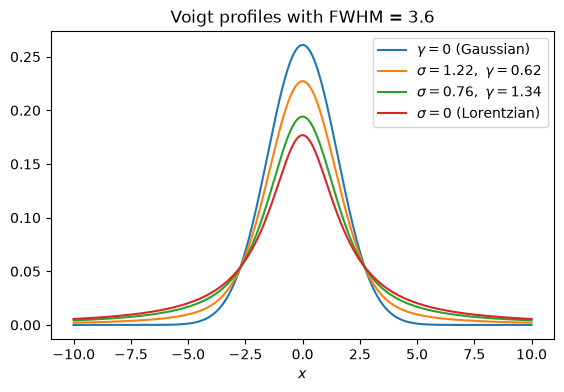

In [22]:
fV = 3.6
fig, ax = plt.subplots(figsize=(6.5, 4))
x = np.linspace(-10, 10, 2001)
ax.plot(x, gaussian(x, fV / (2 * np.sqrt(2 * np.log(2)))), label=r"$\gamma=0$ (Gaussian)")
for r in (0.3, 0.6):
    # 给定洛伦兹 FWHM 占比 r，用数值求根找出使总 FWHM = fV 的尺度
    def total_fwhm(scale):
        s, g = scale * (1 - r) / (2 * np.sqrt(2 * np.log(2))), scale * r / 2
        pk = voigt(0.0, s, g)
        return 2 * brentq(lambda t: voigt(t, s, g) - pk / 2, 0, 100) - fV
    k = brentq(total_fwhm, 0.5, 10)
    s, g = k * (1 - r) / (2 * np.sqrt(2 * np.log(2))), k * r / 2
    ax.plot(x, voigt(x, s, g), label=rf"$\sigma={s:.2f},\ \gamma={g:.2f}$")
ax.plot(x, lorentzian(x, fV / 2), label=r"$\sigma=0$ (Lorentzian)")
ax.set_xlabel("$x$")
ax.set_title("Voigt profiles with FWHM = 3.6")
ax.legend()
plt.show()

## 性质

| 性质 | 结果 |
|---|---|
| 归一化 | $\displaystyle\int_{-\infty}^{\infty}V(x)\,dx=1$（两个归一化函数的卷积） |
| 中位数、众数 | 都在 0（不在原点时都在 $\mu_V$） |
| 均值、方差、偏度、峰度、矩母函数 | **都不存在**：洛伦兹分布除零阶矩外没有矩，Voigt 继承了这一点 |
| 特征函数 | $\varphi(t)=E(e^{ixt})=e^{-\sigma^2t^2/2-\gamma\lvert t\rvert}$ |
| 不在原点时的特征函数 | $\varphi(t)=e^{i(\mu_G+\mu_L)t-\sigma^2t^2/2-\gamma\lvert t\rvert}$ |
| 卷积封闭性 | 两个 Voigt 线形卷积仍是 Voigt 线形 |
| 峰值（补充） | $V(0)=\dfrac{\operatorname{erfcx}\!\left(\gamma/(\sigma\sqrt2)\right)}{\sigma\sqrt{2\pi}}$，其中 $\operatorname{erfcx}(y)=e^{y^2}\operatorname{erfc}(y)$ |

几点说明：

- **特征函数**正是柯西分布的 $e^{-\gamma|t|}$ 与正态分布的 $e^{-\sigma^2t^2/2}$ 的乘积，体现了"卷积的傅里叶变换等于傅里叶变换之积"。矩母函数不存在，特征函数却总是存在。
- **卷积封闭性**：正态分布和柯西分布都是稳定分布，各自在卷积下封闭（只改变尺度），所以 Voigt 分布也封闭。具体来说，两个 Voigt 卷积后，$\sigma^2$ 相加、$\gamma$ 相加、中心相加。从特征函数相乘可以直接看出这一点。
- **峰值公式**来自 $w(iy)=\operatorname{erfcx}(y)$（$y$ 为实数），这一条是补充的。


In [23]:
sigma, gamma = 0.6, 0.4

# 峰值
print("峰值（数值）:", voigt(0.0, sigma, gamma),
      " 峰值（erfcx 公式）:", erfcx(gamma / (sigma * np.sqrt(2))) / (sigma * SQ2PI))

# 特征函数：数值傅里叶积分 vs 解析式（偶函数，只剩余弦项；用 quad 的 weight="cos" 处理振荡积分）
for t in (0.5, 1.0, 2.0):
    num = 2 * quad(voigt, 0, np.inf, args=(sigma, gamma), weight="cos", wvar=t)[0]
    print(f"t={t}: 数值 {num:.6f}  解析 {np.exp(-gamma * abs(t) - sigma**2 * t**2 / 2):.6f}")

# 卷积封闭性：V(σ1,γ1) * V(σ2,γ2) = V(sqrt(σ1²+σ2²), γ1+γ2)
s1, g1, s2, g2 = 0.5, 0.3, 0.8, 0.6
dx = 0.002
x = np.arange(-60, 60, dx)
conv = np.convolve(voigt(x, s1, g1), voigt(x, s2, g2), mode="same") * dx
m = np.abs(x) < 5
print("卷积封闭性 最大偏差:", np.abs(conv - voigt(x, np.hypot(s1, s2), g1 + g2))[m].max())

峰值（数值）: 0.41932160841739824  峰值（erfcx 公式）: 0.41932160841739824
t=0.5: 数值 0.782705  解析 0.782705
t=1.0: 数值 0.559898  解析 0.559898
t=2.0: 数值 0.218712  解析 0.218712
卷积封闭性 最大偏差: 0.00018549746015186774


卷积封闭性那一项的偏差在 $10^{-4}$ 量级，主要是因为数值卷积把区间截断在 $\pm60$ 内，而洛伦兹尾部衰减很慢；区间取得越宽，偏差越小。

## 累积分布函数（CDF）

记 $z$ 同上。对 $x$ 积分可以换成对 $z$ 积分：

$$
F(x_0)=\int_{-\infty}^{x_0}\frac{\operatorname{Re}[w(z)]}{\sigma\sqrt{2\pi}}\,dx
=\operatorname{Re}\!\left[\frac{1}{\sqrt\pi}\int_{z(-\infty)}^{z(x_0)}w(z)\,dz\right]
$$

代入 $w(z)=e^{-z^2}[1-\operatorname{erf}(-iz)]$，不定积分为

$$
\frac{1}{\sqrt\pi}\int w(z)\,dz=\frac{\operatorname{erf}(z)}{2}+\frac{iz^2}{\pi}\,{}_2F_2\!\left(1,1;\tfrac32,2;-z^2\right)
$$

其中 ${}_2F_2$ 是广义超几何函数。为了让 $x\to-\infty$ 时 $F\to0$，积分常数取 $1/2$，于是

$$
F(x)=\operatorname{Re}\!\left[\frac12+\frac{\operatorname{erf}(z)}{2}+\frac{iz^2}{\pi}\,{}_2F_2\!\left(1,1;\tfrac32,2;-z^2\right)\right]
$$

SciPy 没有复变量的 ${}_2F_2$，可以用 `mpmath`（安装 `sympy` 时会一起装上，也可以 `pip install mpmath`）：

In [24]:
import mpmath as mp


def voigt_cdf(x, sigma, gamma, mu=0.0):
    """Voigt 的累积分布函数（解析式，mpmath 计算 2F2）"""
    z = mp.mpc(x - mu, gamma) / (sigma * mp.sqrt(2))
    val = mp.mpf(1) / 2 + mp.erf(z) / 2 + 1j * z**2 / mp.pi * mp.hyp2f2(1, 1, 1.5, 2, -z**2)
    return float(mp.re(val))


mu, sigma, gamma = 10.0, 1.3, 2.5
for x0 in (5, 10, 12, 20):
    num = quad(voigt, -np.inf, x0, args=(sigma, gamma, mu))[0]
    print(f"F({x0}) 解析 {voigt_cdf(x0, sigma, gamma, mu):.10f}   数值积分 {num:.10f}")

F(5) 解析 0.1551501031   数值积分 0.1551501031
F(10) 解析 0.5000000000   数值积分 0.5000000000
F(12) 解析 0.6929005540   数值积分 0.6929005540
F(20) 解析 0.9207759641   数值积分 0.9207759641


## 导数

记 $x_c=x-\mu_V$，$\Re_w=\operatorname{Re}[w(z)]$，$\Im_w=\operatorname{Im}[w(z)]$。对 $x$ 的一阶和二阶导数：

$$
\frac{\partial V}{\partial x}=-\frac{\operatorname{Re}[z\,w(z)]}{\sigma^2\sqrt\pi}
=\frac{1}{\sigma^3\sqrt{2\pi}}\left(\gamma\,\Im_w-x_c\,\Re_w\right)
$$

$$
\frac{\partial^2 V}{\partial x^2}
=-\frac{1}{\sigma^5\sqrt{2\pi}}\left[\gamma\left(2x_c\,\Im_w-\sigma\sqrt{\tfrac{2}{\pi}}\right)+\left(\gamma^2+\sigma^2-x_c^2\right)\Re_w\right]
$$

（第一个等号由 $w'(z)=-2z\,w(z)+\frac{2i}{\sqrt\pi}$ 推出。）

### 对参数的偏导数：用于非线性最小二乘拟合

拟合 Voigt 峰时，要对峰位 $\mu_V$、$\sigma$、$\gamma$ 求偏导数（雅可比矩阵）。与其用有限差分近似，不如直接用解析式：

$$
\frac{\partial V}{\partial\mu_V}=-\frac{\partial V}{\partial x}=\frac{1}{\sigma^3\sqrt{2\pi}}\left(x_c\,\Re_w-\gamma\,\Im_w\right)
$$

$$
\frac{\partial V}{\partial\sigma}=\frac{1}{\sigma^4\sqrt{2\pi}}\left[\left(x_c^2-\gamma^2-\sigma^2\right)\Re_w-2x_c\gamma\,\Im_w+\gamma\sigma\sqrt{\tfrac{2}{\pi}}\right]
$$

$$
\frac{\partial V}{\partial\gamma}=-\frac{1}{\sigma^3\sqrt{2\pi}}\left(\sigma\sqrt{\tfrac{2}{\pi}}-x_c\,\Im_w-\gamma\,\Re_w\right)
$$

这些式子只用到 $\Re_w$ 和 $\Im_w$ 的乘法和加法。计算 $V$ 本身时 $w(z)$ 已经算出来了，所以求偏导几乎不额外花时间；有限差分则每个参数都要多算一次 $w(z)$。

$\mu_V$ 和 $\gamma$ 在 $z$ 里的地位相似（分别是实部和虚部的偏移），所以它们的偏导数形式结构相近，但画出来的曲线完全不同。$\sigma$ 和 $\gamma$ 都是宽度参数，它们的偏导数曲线反而更相似：这也是两者在拟合中容易相关的原因。

维基百科还给出了 $\partial V/\partial x$ 和 $\partial^2V/\partial x^2$ 对三个参数的偏导数，用于拟合导数谱，这里不再列出。

∂V/∂x  最大偏差: 2.249715004399395e-06
∂V/∂μ  最大偏差: 5.186476508683979e-11
∂V/∂σ  最大偏差: 6.406630477864828e-11
∂V/∂γ  最大偏差: 3.053517508289083e-11


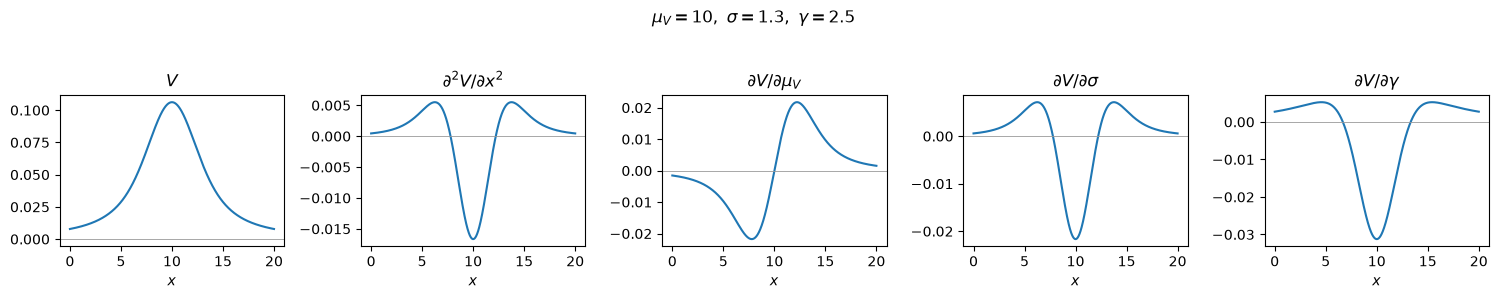

In [25]:
def voigt_with_grad(x, mu, sigma, gamma):
    """返回 V 及其对 x、μ、σ、γ 的偏导数，以及对 x 的二阶导数"""
    xc = x - mu
    z = (xc + 1j * gamma) / (sigma * np.sqrt(2))
    w = wofz(z)
    Rw, Iw = w.real, w.imag
    c = np.sqrt(2 / np.pi)
    V = Rw / (sigma * SQ2PI)
    dV_dx = (gamma * Iw - xc * Rw) / (sigma**3 * SQ2PI)
    d2V_dx2 = -(gamma * (2 * xc * Iw - sigma * c) + (gamma**2 + sigma**2 - xc**2) * Rw) / (sigma**5 * SQ2PI)
    dV_dmu = -dV_dx
    dV_dsigma = ((xc**2 - gamma**2 - sigma**2) * Rw - 2 * xc * gamma * Iw + gamma * sigma * c) / (sigma**4 * SQ2PI)
    dV_dgamma = -(sigma * c - xc * Iw - gamma * Rw) / (sigma**3 * SQ2PI)
    return V, dV_dx, d2V_dx2, dV_dmu, dV_dsigma, dV_dgamma


# 与中心差分对比
mu, sigma, gamma = 10.0, 1.3, 2.5
x = np.linspace(0, 20, 2001)
V, dx_, d2x, dmu, dsig, dgam = voigt_with_grad(x, mu, sigma, gamma)
h = 1e-6
f = lambda m, s, g: voigt(x, s, g, m)
print("∂V/∂x  最大偏差:", np.abs(dx_ - np.gradient(V, x)).max())
print("∂V/∂μ  最大偏差:", np.abs(dmu - (f(mu + h, sigma, gamma) - f(mu - h, sigma, gamma)) / (2 * h)).max())
print("∂V/∂σ  最大偏差:", np.abs(dsig - (f(mu, sigma + h, gamma) - f(mu, sigma - h, gamma)) / (2 * h)).max())
print("∂V/∂γ  最大偏差:", np.abs(dgam - (f(mu, sigma, gamma + h) - f(mu, sigma, gamma - h)) / (2 * h)).max())

fig, axes = plt.subplots(1, 5, figsize=(15, 2.8), sharex=True)
for ax, (y, name) in zip(axes, [(V, "$V$"), (d2x, r"$\partial^2V/\partial x^2$"), (dmu, r"$\partial V/\partial\mu_V$"),
                                (dsig, r"$\partial V/\partial\sigma$"), (dgam, r"$\partial V/\partial\gamma$")]):
    ax.plot(x, y)
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_title(name)
    ax.set_xlabel("$x$")
fig.suptitle(r"$\mu_V=10,\ \sigma=1.3,\ \gamma=2.5$", y=1.05)
plt.tight_layout()
plt.show()

## FWHM

两个分量各自的 FWHM：

$$
f_G=2\sigma\sqrt{2\ln2},\qquad f_L=2\gamma
$$

Voigt 线形的 FWHM $f_V$ 没有精确闭式，常用近似：

| 近似公式 | 来源 | 精度 |
|---|---|---|
| $f_V\approx\dfrac{f_L}{2}+\sqrt{\dfrac{f_L^2}{4}+f_G^2}$ | Whiting (1968) | 约 1.2%；纯高斯和纯洛伦兹时精确 |
| $f_V\approx0.5346\,f_L+\sqrt{0.2166\,f_L^2+f_G^2}$ | Olivero & Longbothum (1977)，最初来自 Kielkopf (1973) | 约 0.02% |

关于 Olivero–Longbothum 的系数：原论文常被引用的是 0.5346 和 0.2166，当前版本的维基百科写的是 0.5343 和 0.2169。我把洛伦兹占比从 0.1% 扫到 99.9%，两组系数的最大相对误差都约为 0.023%，几乎没有差别，用哪组都可以。同一篇论文里还有一个更精确（约 0.012%）但复杂得多的表达式。

$f_V$ 总是介于 $\max(f_G,f_L)$ 和 $f_G+f_L$ 之间。在接近高斯（$f_L\ll f_G$）或接近洛伦兹（$f_G\ll f_L$）的极限下，半宽还有级数展开（Wang et al. 2022；Wuttke 2025），系数由递推公式给出。


Whiting (1968)             最大相对误差: 1.1958%
Olivero (0.5346, 0.2166)   最大相对误差: 0.0237%
Olivero (0.5343, 0.2169)   最大相对误差: 0.0232%


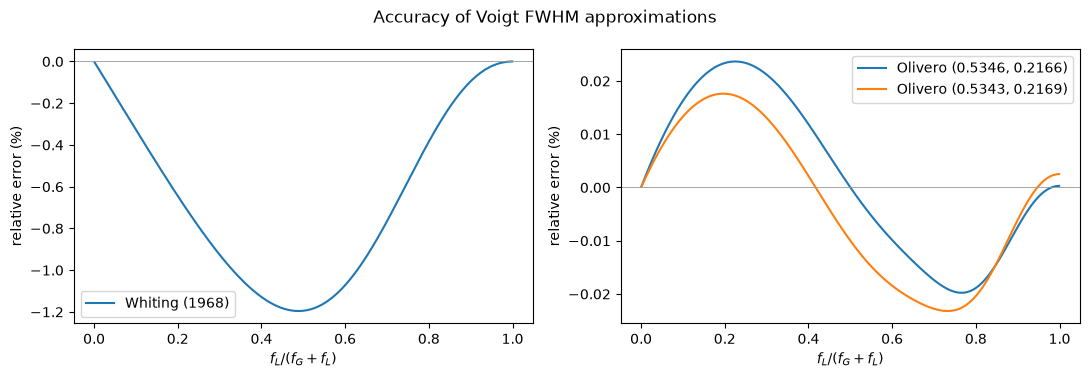

In [26]:
def fwhm_numeric(sigma, gamma):
    peak = voigt(0.0, sigma, gamma)
    hw = brentq(lambda x: voigt(x, sigma, gamma) - peak / 2, 0, 50 * (sigma + gamma))
    return 2 * hw


def fwhm_whiting(fG, fL):
    return fL / 2 + np.sqrt(fL**2 / 4 + fG**2)


def fwhm_olivero(fG, fL, c1=0.5346, c2=0.2166):
    return c1 * fL + np.sqrt(c2 * fL**2 + fG**2)


# 扫描洛伦兹成分所占的比例，比较各近似的相对误差
ratio = np.linspace(0.001, 0.999, 999)         # fL / (fG + fL)
fG, fL = 1 - ratio, ratio
sig, gam = fG / (2 * np.sqrt(2 * np.log(2))), fL / 2
exact = np.array([fwhm_numeric(s, g) for s, g in zip(sig, gam)])

approx = {
    "Whiting (1968)": fwhm_whiting(fG, fL),
    "Olivero (0.5346, 0.2166)": fwhm_olivero(fG, fL),
    "Olivero (0.5343, 0.2169)": fwhm_olivero(fG, fL, 0.5343, 0.2169),
}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for name, val in approx.items():
    err = 100 * (val - exact) / exact
    (ax1 if name.startswith("Whiting") else ax2).plot(ratio, err, label=name)
    print(f"{name:<26} 最大相对误差: {np.abs(err).max():.4f}%")
for ax in (ax1, ax2):
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xlabel(r"$f_L/(f_G+f_L)$")
    ax.set_ylabel("relative error (%)")
    ax.legend()
fig.suptitle("Accuracy of Voigt FWHM approximations")
plt.tight_layout()
plt.show()

## Voigt 函数 $U$、$V$、$H$

在天体物理和辐射传输里，常用的是 Voigt 函数（DLMF §7.19）：

$$
U(x,t)+iV(x,t)=\sqrt{\frac{\pi}{4t}}\,e^{z^2}\operatorname{erfc}(z)=\sqrt{\frac{\pi}{4t}}\,w(iz),\qquad z=\frac{1-ix}{2\sqrt t}
$$

以及线展宽函数（line broadening function，也叫 Voigt–Hjerting 函数）：

$$
H(a,u)=\frac{U\!\left(\frac{u}{a},\frac{1}{4a^2}\right)}{\sqrt\pi\,a}
$$

（注意这里的 $V(x,t)$ 是 Voigt 函数的虚部，和 Voigt 线形 $V(x;\sigma,\gamma)$ 不是同一个东西。）

$H$ 与 Voigt 线形的关系：

$$
V(x;\sigma,\gamma)=\frac{H(a,u)}{\sqrt{2\pi}\,\sigma},\qquad u=\frac{x}{\sqrt2\,\sigma},\quad a=\frac{\gamma}{\sqrt2\,\sigma}
$$

由此 $H(a,u)=\operatorname{Re}[w(u+ia)]$。$H$ 的峰值不是 1，$H(0,u)=e^{-u^2}$（纯高斯）。

In [27]:
def H_from_U(a, u):
    """按 U、V 的定义计算 H(a, u)"""
    x, t = u / a, 1 / (4 * a**2)
    z = (1 - 1j * x) / (2 * np.sqrt(t))
    UV = np.sqrt(np.pi / (4 * t)) * wofz(1j * z)
    return UV.real / (np.sqrt(np.pi) * a)


a = 0.3
u = np.linspace(-4, 4, 9)
print("H 两种算法最大偏差:", np.abs(H_from_U(a, u) - wofz(u + 1j * a).real).max())

sigma = 0.7
x = np.sqrt(2) * sigma * u
print("V = H/(√(2π)σ) 最大偏差:",
      np.abs(wofz(u + 1j * a).real / (SQ2PI * sigma) - voigt(x, sigma, a * np.sqrt(2) * sigma)).max())

H 两种算法最大偏差: 1.1102230246251565e-16
V = H/(√(2π)σ) 最大偏差: 1.474514954580286e-17


### Tepper-García 近似

Tepper-García (2006) 从精确的线展宽函数出发，截断幂级数展开，得到一个由指数函数和有理函数组成的近似：

$$
T(a,u)=R-\frac{a}{\sqrt\pi\,P}\left[R^2\left(4P^2+7P+4+Q\right)-Q-1\right],\qquad P\equiv u^2,\ Q\equiv\frac{3}{2P},\ R\equiv e^{-P}
$$

也就是说，线展宽函数可以近似看成一个纯高斯加上一个与 $a$ 成正比的修正项；$a$ 编码了吸收介质的微观性质（阻尼）。由于截断得早，误差本身是 $\mathcal O(a)$ 量级。维基百科说：只要 $a\lesssim10^{-4}$，在整个波长范围内相对误差都 $\lesssim10^{-4}$。这个近似计算快，在类星体吸收线分析中用得很多。

我的实测：在线心（$|u|<2$）内，相对误差约为 $2a$（$a=10^{-4}$ 时约 $2\times10^{-4}$），与 $\mathcal O(a)$ 的说法一致；但在高斯核心向洛伦兹线翼过渡的区域（$u\approx3$–$4$），相对误差可以达到 1%–3%，而且 $a$ 再小也降不下去。不过那里 $H$ 本身只有 $10^{-6}$ 量级，绝对误差非常小。所以"相对误差 $\lesssim10^{-4}$"的说法只在线心附近成立。

a=1e-06: |u|<2 内最大相对误差 2.3e-06，全范围最大 1.0e-02（在 u≈4.39）
a=0.0001: |u|<2 内最大相对误差 2.3e-04，全范围最大 2.0e-02（在 u≈3.71）
a=0.001: |u|<2 内最大相对误差 2.3e-03，全范围最大 3.3e-02（在 u≈3.27）


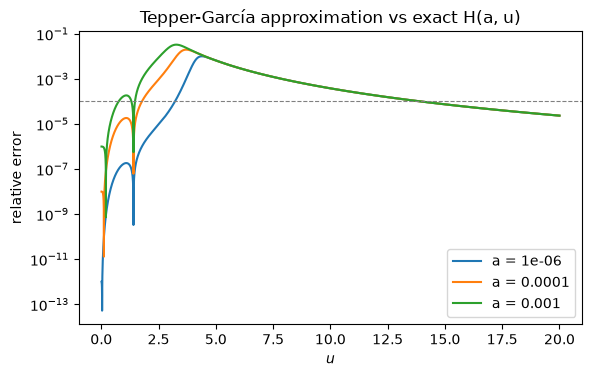

In [28]:
def tepper_garcia(a, u):
    P = u**2
    Q = 1.5 / P
    R = np.exp(-P)
    return R - a / (np.sqrt(np.pi) * P) * (R**2 * (4 * P**2 + 7 * P + 4 + Q) - Q - 1)


u = np.linspace(0.01, 20, 20000)            # u=0 处公式有 0/0，需单独处理，这里从 0.01 开始
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for a in (1e-6, 1e-4, 1e-3):
    H = wofz(u + 1j * a).real
    rel = np.abs(tepper_garcia(a, u) - H) / H
    ax.semilogy(u, rel, label=f"a = {a:g}")
    print(f"a={a:g}: |u|<2 内最大相对误差 {rel[u < 2].max():.1e}，全范围最大 {rel.max():.1e}（在 u≈{u[rel.argmax()]:.2f}）")
ax.axhline(1e-4, color="0.5", ls="--", lw=0.8)
ax.set_xlabel("$u$")
ax.set_ylabel("relative error")
ax.set_title("Tepper-García approximation vs exact H(a, u)")
ax.legend()
plt.show()

## 伪 Voigt 近似（pseudo-Voigt）

因为计算 Faddeeva 函数代价较高，实际中常用高斯和洛伦兹的**线性组合**（而不是卷积）来近似 Voigt，这在计算实验谱线线形时很常见：

$$
V_p(x;f)=\eta\,L(x;f)+(1-\eta)\,G(x;f),\qquad 0<\eta<1
$$

这里 $L$ 和 $G$ 取**同一个** FWHM $f$。$\eta$ 有多种取法（Wertheim 1974、Sánchez-Bajo 1997、Liu 2001、Di Rocco 2012 等）。一个简单的公式（Thompson–Cox–Hastings 1987；Ida 2000）精度约为 1%：

$$
\eta=1.36603\,\frac{f_L}{f}-0.47719\left(\frac{f_L}{f}\right)^2+0.11116\left(\frac{f_L}{f}\right)^3
$$

$$
f=\left(f_G^5+2.69269\,f_G^4f_L+2.42843\,f_G^3f_L^2+4.47163\,f_G^2f_L^3+0.07842\,f_Gf_L^4+f_L^5\right)^{1/5}
$$

TCH 这篇是 Al₂O₃ 同步辐射 XRD 的 Rietveld 精修论文，这就是 XRD 精修里常说的 TCH pseudo-Voigt 峰形。XPS 软件里的 GL 混合线形思路类似，但比例 $\eta$ 通常直接作为拟合参数，不由上面的公式决定。

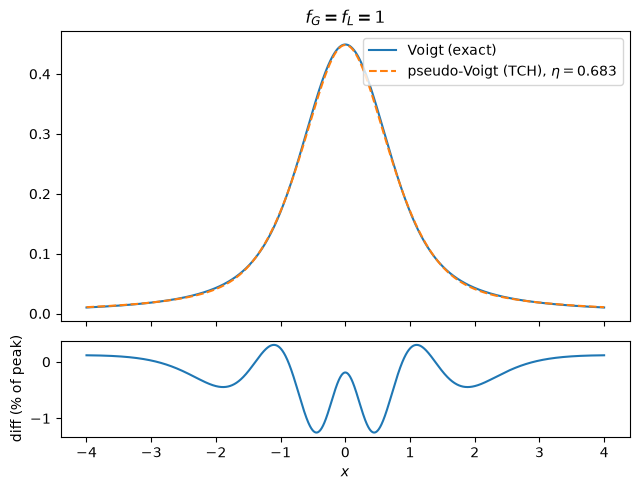

最大偏差占峰值的 1.25%


In [29]:
def pseudo_voigt_tch(x, fG, fL):
    f = (fG**5 + 2.69269 * fG**4 * fL + 2.42843 * fG**3 * fL**2
         + 4.47163 * fG**2 * fL**3 + 0.07842 * fG * fL**4 + fL**5) ** 0.2
    eta = 1.36603 * (fL / f) - 0.47719 * (fL / f) ** 2 + 0.11116 * (fL / f) ** 3
    s = f / (2 * np.sqrt(2 * np.log(2)))
    return eta * lorentzian(x, f / 2) + (1 - eta) * gaussian(x, s), eta


fG, fL = 1.0, 1.0
x = np.linspace(-4, 4, 2001)
v = voigt(x, fG / (2 * np.sqrt(2 * np.log(2))), fL / 2)
pv, eta = pseudo_voigt_tch(x, fG, fL)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(x, v, label="Voigt (exact)")
ax1.plot(x, pv, "--", label=rf"pseudo-Voigt (TCH), $\eta={eta:.3f}$")
ax1.legend()
ax1.set_title(r"$f_G = f_L = 1$")
ax2.plot(x, 100 * (pv - v) / v.max())
ax2.set_ylabel("diff (% of peak)")
ax2.set_xlabel("$x$")
plt.tight_layout()
plt.show()

print(f"最大偏差占峰值的 {np.abs(pv - v).max() / v.max():.2%}")

### 不对称伪 Voigt（Martinelli 函数）

仿照分裂正态分布（split normal distribution），让峰两侧的宽度不同：形式同上，但 $f$ 分段取值，$x<0$ 时 $f=f_1$，$x\ge0$ 时 $f=f_2$。$f_1\to f_2$ 时退化为对称的伪 Voigt。它曾用于描述共振非弹性 X 射线散射（RIXS）谱仪中的弹性散射峰。

如果直接套用面积归一化的 $G$ 和 $L$，峰两侧的峰高不同，$x=0$ 处会出现跳变。所以实际使用时，一般改用峰高为 1 的形式来组合，这样峰顶是连续的（下面的代码就是这样写的），需要面积时再另外归一化。

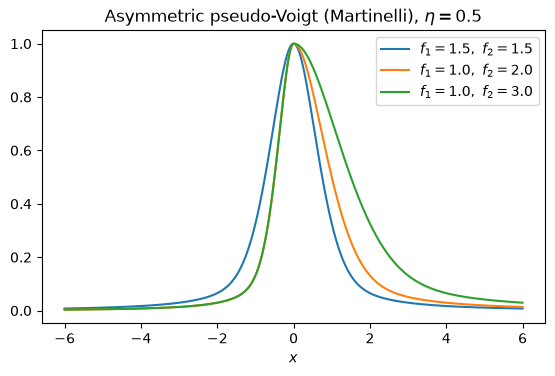

In [30]:
def martinelli(x, f1, f2, eta):
    """不对称伪 Voigt：x<0 用宽度 f1，x>=0 用宽度 f2。
    用峰高为 1 的高斯和洛伦兹组合，保证 x=0 处连续"""
    f = np.where(x < 0, f1, f2)
    g = np.exp(-4 * np.log(2) * x**2 / f**2)
    l = 1 / (1 + 4 * x**2 / f**2)
    return eta * l + (1 - eta) * g


x = np.linspace(-6, 6, 1201)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for f1, f2 in [(1.5, 1.5), (1.0, 2.0), (1.0, 3.0)]:
    ax.plot(x, martinelli(x, f1, f2, 0.5), label=rf"$f_1={f1},\ f_2={f2}$")
ax.set_xlabel("$x$")
ax.set_title(r"Asymmetric pseudo-Voigt (Martinelli), $\eta=0.5$")
ax.legend()
plt.show()

## 应用：用 Voigt 线形拟合谱峰（带解析雅可比）

实际拟合时还要加上峰面积 $A$、峰位 $\mu_V$ 和背景 $b$：$y=A\,V(x;\mu_V,\sigma,\gamma)+b$。把上面的解析偏导数传给 `curve_fit` 的 `jac` 参数：

 area: 拟合 5.0046 ± 0.0258   真值 5.0
   mu: 拟合 0.7008 ± 0.0022   真值 0.7
sigma: 拟合 0.8034 ± 0.0092   真值 0.8
gamma: 拟合 0.4993 ± 0.0137   真值 0.5
   bg: 拟合 0.0992 ± 0.0013   真值 0.1
FWHM ≈ 2.4818  (fG = 1.892, fL = 0.999)
σ 与 γ 的相关系数: -0.9513681972519805


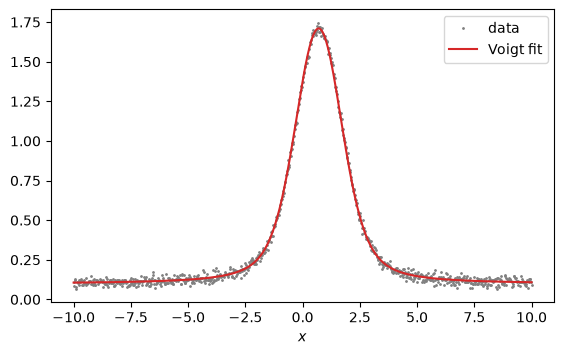

In [31]:
def model(x, area, mu, sigma, gamma, bg):
    return area * voigt(x, sigma, gamma, mu) + bg


def model_jac(x, area, mu, sigma, gamma, bg):
    V, _, _, dmu, dsig, dgam = voigt_with_grad(x, mu, sigma, gamma)
    return np.column_stack([V, area * dmu, area * dsig, area * dgam, np.ones_like(x)])


rng = np.random.default_rng(42)
x = np.linspace(-10, 10, 801)
true = dict(area=5.0, mu=0.7, sigma=0.8, gamma=0.5, bg=0.1)
y = model(x, **true) + rng.normal(0, 0.02, x.size)

p0 = [y.sum() * (x[1] - x[0]), x[np.argmax(y)], 1.0, 1.0, y.min()]   # 粗略初值
bounds = ([0, -np.inf, 1e-6, 1e-6, -np.inf], np.inf)
popt, pcov = curve_fit(model, x, y, p0=p0, jac=model_jac, bounds=bounds)
perr = np.sqrt(np.diag(pcov))

for (name, t), p, e in zip(true.items(), popt, perr):
    print(f"{name:>5}: 拟合 {p:.4f} ± {e:.4f}   真值 {t}")

fG = 2 * popt[2] * np.sqrt(2 * np.log(2))
fL = 2 * popt[3]
print(f"FWHM ≈ {fwhm_olivero(fG, fL):.4f}  (fG = {fG:.3f}, fL = {fL:.3f})")
print("σ 与 γ 的相关系数:", pcov[2, 3] / np.sqrt(pcov[2, 2] * pcov[3, 3]))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(x, y, ".", ms=2, color="0.5", label="data")
ax.plot(x, model(x, *popt), color="C3", label="Voigt fit")
ax.legend()
ax.set_xlabel("$x$")
plt.show()

拟合时要注意，$\sigma$ 和 $\gamma$ 有很强的负相关（都在控制峰宽，上面打印的相关系数可以看出来）：数据噪声大或者尾部采样范围不够时，两者可能分不开，误差会很大。如果高斯部分主要来自仪器分辨率，可以先单独标定它，拟合时固定 $\sigma$。

## 参考文献（选自维基百科）

1. W. Voigt (1912), *Sitzungsbericht der Bayerischen Akademie der Wissenschaften* 25, 603.
2. N. M. Temme (2010), "Voigt function," *NIST Handbook of Mathematical Functions*, §7.19. <https://dlmf.nist.gov/7.19>
3. T. Tepper-García (2006), *MNRAS* 369(4), 2025–2035. doi:10.1111/j.1365-2966.2006.10450.x
4. P. Thompson, D. E. Cox, J. B. Hastings (1987), *J. Appl. Cryst.* 20(2), 79–83. doi:10.1107/S0021889887087090
5. T. Ida, M. Ando, H. Toraya (2000), *J. Appl. Cryst.* 33(6), 1311–1316. doi:10.1107/s0021889800010219
6. E. E. Whiting (1968), *JQSRT* 8(6), 1379–1384. doi:10.1016/0022-4073(68)90081-2
7. J. J. Olivero, R. L. Longbothum (1977), *JQSRT* 17(2), 233–236. doi:10.1016/0022-4073(77)90161-3
8. J. F. Kielkopf (1973), *JOSA* 63(8), 987. doi:10.1364/JOSA.63.000987
9. G. K. Wertheim et al. (1974), *Rev. Sci. Instrum.* 45(11), 1369–1371. doi:10.1063/1.1686503